In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns; sns.set(style="ticks")
from pathlib import Path

# Scientific stack
import scipy
from scipy import sparse
import sklearn
from sklearn.decomposition import PCA
from sklearn.manifold import MDS, TSNE          # ← NEW: scikit-learn’s t-SNE

# House-keeping
import pickle
import sys
import matplotlib

# Optional: fix randomness for full reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# ------------------------------------------------------------------
# Later in the notebook, replace each call like:
#     tsne_default = fast_tsne(X, seed=42)
# with:
#     tsne_default = TSNE(
#         n_components=2,
#         perplexity=30,
#         metric="euclidean",
#         init="random",
#         random_state=RANDOM_STATE,
#     ).fit_transform(X)
# ------------------------------------------------------------------

In [2]:
print('Python version', sys.version)
print('Numpy', np.__version__)
print('Matplotlib', matplotlib.__version__)
print('Seaborn', sns.__version__)
print('Pandas', pd.__version__)
print('Scipy', scipy.__version__)
print('Sklearn', sklearn.__version__)

Python version 3.10.18 (main, Jun  5 2025, 13:14:17) [GCC 11.2.0]
Numpy 2.2.5
Matplotlib 3.10.0
Seaborn 0.13.2
Pandas 2.2.3
Scipy 1.15.3
Sklearn 1.7.0


In [3]:
%%time

# Load the Allen institute data. This takes a few minutes

# This function is needed because using Pandas to load these files in one go 
# can eat up a lot of RAM. So we are doing it in chunks, and converting each
# chunk to the sparse matrix format on the fly.
def sparseload(filenames):
    genes = []
    sparseblocks = []
    areas = []
    cells = []
    for chunk1,chunk2 in zip(pd.read_csv(filenames[0], chunksize=1000, index_col=0, na_filter=False),
                             pd.read_csv(filenames[1], chunksize=1000, index_col=0, na_filter=False)):
        if len(cells)==0:
            cells = np.concatenate((chunk1.columns, chunk2.columns))
            areas = [0]*chunk1.columns.size + [1]*chunk2.columns.size
        
        genes.extend(list(chunk1.index))
        sparseblock1 = sparse.csr_matrix(chunk1.values.astype(float))
        sparseblock2 = sparse.csr_matrix(chunk2.values.astype(float))
        sparseblock = sparse.hstack((sparseblock1,sparseblock2), format='csr')
        sparseblocks.append([sparseblock])
        print('.', end='', flush=True)
    print(' done')
    counts = sparse.bmat(sparseblocks)
    return (counts.T, np.array(genes), cells, np.array(areas))

filenames = ['./data/tasic-nature/mouse_VISp_2018-06-14_exon-matrix.csv',
             './data/tasic-nature/mouse_ALM_2018-06-14_exon-matrix.csv']
counts, genes, cells, areas = sparseload(filenames)

genesDF = pd.read_csv('./data/tasic-nature/mouse_VISp_2018-06-14_genes-rows.csv')
ids     = genesDF['gene_entrez_id'].tolist()
symbols = genesDF['gene_symbol'].tolist()
id2symbol = dict(zip(ids, symbols))
genes = np.array([id2symbol[g] for g in genes])

clusterInfo = pd.read_csv('./data/tasic-sample_heatmap_plot_data.csv')
goodCells  = clusterInfo['sample_name'].values
ids        = clusterInfo['cluster_id'].values
labels     = clusterInfo['cluster_label'].values
colors     = clusterInfo['cluster_color'].values

clusterNames  = np.array([labels[ids==i+1][0] for i in range(np.max(ids))])
clusterColors = np.array([colors[ids==i+1][0] for i in range(np.max(ids))])
clusters   = np.copy(ids) - 1

ind = np.array([np.where(cells==c)[0][0] for c in goodCells])
counts = counts[ind, :]

tasic2018 = {'counts': counts, 'genes': genes, 'clusters': clusters, 'areas': areas, 
             'clusterColors': clusterColors, 'clusterNames': clusterNames}
counts = []

.............................................. done
CPU times: user 51.9 s, sys: 5.85 s, total: 57.7 s
Wall time: 58.7 s


In [4]:
import os
os.getcwd()

'/home/hongrui_liu/learning/tsne/rna-seq-tsne'

In [5]:
print('Number of cells:', tasic2018['counts'].shape[0])
print('Number of cells from ALM:', np.sum(tasic2018['areas']==0))
print('Number of cells from VISp:', np.sum(tasic2018['areas']==1))
print('Number of clusters:', np.unique(tasic2018['clusters']).size)
print('Number of genes:', tasic2018['counts'].shape[1])
print('Fraction of zeros in the data matrix: {:.2f}'.format(
    tasic2018['counts'].size/np.prod(tasic2018['counts'].shape)))

Number of cells: 23822
Number of cells from ALM: 15413
Number of cells from VISp: 10068
Number of clusters: 133
Number of genes: 45768
Fraction of zeros in the data matrix: 0.20


In [6]:
genes

array(['0610005C13Rik', '0610006L08Rik', '0610007P14Rik', ..., 'n-R5s144',
       'n-R5s146', 'n-R5s149'], shape=(45768,), dtype='<U28')

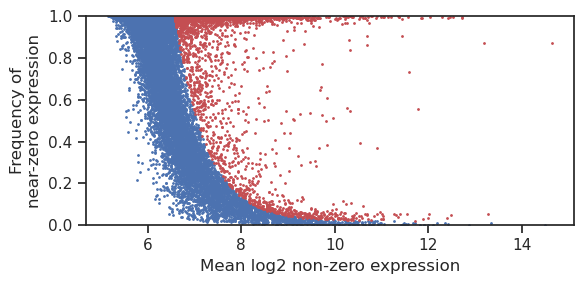

In [7]:
# ──────────────────────────────────────────────────
# Feature-selection helpers (SciPy sparse-friendly)
# ──────────────────────────────────────────────────

def nearZeroRate(data, threshold=0):
    # Fraction of cells where expression ≤ threshold
    return 1.0 - (data > threshold).mean(axis=0).A1          # 1-D array

def meanLogExpression(data, threshold=0, atleast=10):
    nonZeros = (data > threshold).sum(axis=0).A1             # #cells detected
    N = data.shape[0]

    # keep only entries above threshold, then log-transform in-place
    A = data.multiply(data > threshold).astype(np.float32)
    with np.errstate(divide='ignore'):
        A.data = np.log2(A.data, dtype=A.data.dtype)

    meanExpr = np.full(data.shape[1], np.nan, dtype=np.float32)
    detected = nonZeros >= atleast
    meanExpr[detected] = (A[:, detected].mean(axis=0).A1) / (nonZeros[detected] / N)
    return meanExpr

def featureSelection(meanLogExpression, nearZeroRate,
                     yoffset=.02, decay=1.5, n=3000):
    low, up, xoffset = 0.0, 10.0, 5.0
    nonan = ~np.isnan(meanLogExpression)

    for _ in range(100):
        selected = np.zeros_like(nearZeroRate, dtype=bool)
        selected[nonan] = nearZeroRate[nonan] > (
            np.exp(-decay * meanLogExpression[nonan] + xoffset) + yoffset
        )
        k = selected.sum()
        if k == n:
            break
        if k < n:
            up = xoffset
            xoffset = 0.5 * (low + xoffset)
        else:
            low = xoffset
            xoffset = 0.5 * (xoffset + up)
    return selected

# ------------------------------------------------------------------
x = meanLogExpression(tasic2018['counts'], threshold=32)
y = nearZeroRate(tasic2018['counts'], threshold=32)
selectedGenes = featureSelection(x, y, n=3000)

plt.figure(figsize=(6, 3))
plt.scatter(x[~selectedGenes], y[~selectedGenes], s=1)
plt.scatter(x[selectedGenes],  y[selectedGenes],  s=1, color='r')
plt.xlabel('Mean log2 non-zero expression')
plt.ylabel('Frequency of\nnear-zero expression')
plt.ylim(0, 1)
plt.tight_layout()

In [8]:
%%time
# ───────────────────────────────────────────────
# 1. Subset to the 3 000 selected genes (CSR)
# ───────────────────────────────────────────────
counts3k = tasic2018['counts'][:, selectedGenes].tocsr()

# ───────────────────────────────────────────────
# 2. Library-size normalization → CPM
# ───────────────────────────────────────────────
# Sum UMI counts per cell  →  1-D float32 vector
librarySizes = np.asarray(counts3k.sum(axis=1)).ravel().astype(np.float32)   # shape (n_cells,)

# Scale each cell’s column block WITHOUT densifying the matrix
scaling = 1e6 / librarySizes                                     # broadcast multiplier
CPM = counts3k.multiply(scaling[:, None])                        # still sparse (CSR, float32)

# 3. Log2 transform and densify (last possible moment)
logCPM = np.log2(CPM.toarray() + 1.0)                            # dense (n_cells × 3 000)

# 4. PCA (50 dims) with fixed sign convention
pca = PCA(
    n_components=50,
    svd_solver='full',
    random_state=42,      # makes results reproducible
)
pca.fit(logCPM)

# Flip PCs so each component has a positive overall loading
flipSigns = pca.components_.sum(axis=1) < 0
X = pca.transform(logCPM).astype(np.float32)
X[:, flipSigns] *= -1     # shape: (n_cells, 50)

print('Shape of the resulting matrix:', X.shape)


Shape of the resulting matrix: (23822, 50)
CPU times: user 1min 4s, sys: 1.56 s, total: 1min 6s
Wall time: 6.43 s


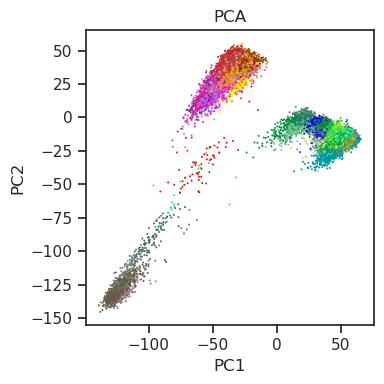

In [9]:
# PCA scatter plot: first two principal components

# 1. Pull the per-cell cluster IDs that match the PCA matrix X
cell_clusters = tasic2018['clusters']          # after earlier filtering, same length as X
cell_colors   = tasic2018['clusterColors'][cell_clusters]

# 2. Plot
plt.figure(figsize=(4, 4))
plt.scatter(
    X[:, 0], X[:, 1],
    c=cell_colors,            # hex codes, one per point
    s=2,                      # point size
    edgecolors='none',        # avoids matplotlib 3.9 warning for unfilled markers
)
plt.title('PCA')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.tight_layout()
plt.savefig('pca_plot.pdf', format='pdf', dpi=300, bbox_inches='tight')

1,397 cells in the selected corner
CPU times: user 1.4 s, sys: 10.7 ms, total: 1.41 s
Wall time: 114 ms


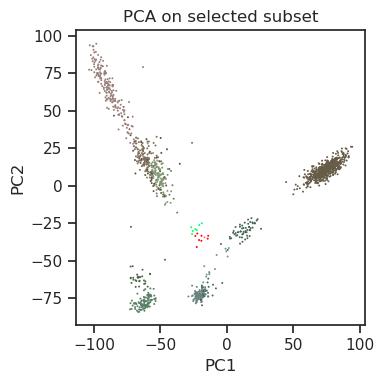

In [10]:
%%time
# 1. Pick the “south-west” corner of the global PCA
subset = (X[:, 0] < -50) & (X[:, 1] < -50)     # boolean mask
n_sub   = subset.sum()
print(f'{n_sub:,} cells in the selected corner')

if n_sub == 0:
    raise ValueError("Subset mask is empty—adjust the PC thresholds.")

# 2. PCA on the subset only

pca_sub = PCA(
    n_components=2,
    svd_solver='full',        # forces deterministic full SVD
    random_state=42,          # has no effect with 'full', but harmless
)
Xsubset = pca_sub.fit_transform(X[subset, :].astype(np.float32))

# 3. Scatter plot

plt.figure(figsize=(4, 4))
plt.scatter(
    Xsubset[:, 0], Xsubset[:, 1],
    c=tasic2018['clusterColors'][tasic2018['clusters'][subset]],
    s=2, edgecolors='none'
)
plt.title('PCA on selected subset')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.tight_layout()
plt.savefig('pca_subset_plot.pdf', format='pdf', dpi=300, bbox_inches='tight')

/home/hongrui_liu/miniconda3/envs/rnaseq/lib/python3.10/site-packages/sklearn/manifold/_mds.py:677: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9.
  warnings.warn(


CPU times: user 2.38 s, sys: 44.6 ms, total: 2.43 s
Wall time: 192 ms


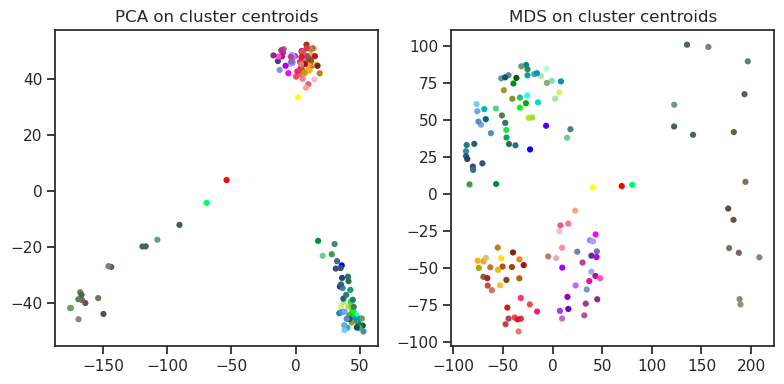

In [11]:
%%time
# PCA and MDS of cluster centroids

# 1. Compute per-cluster means (vectorised, float32)
clusters = tasic2018['clusters']                       # length = n_cells
C        = clusters.max() + 1                          # number of clusters
clusterMeans = np.vstack([
    X[clusters == c].mean(axis=0).astype(np.float32)   # row = centroid in PC-space
    for c in range(C)
])

# 2. Low-dim representations
pca_centroids = PCA(
    n_components=2,
    svd_solver='full'
).fit_transform(clusterMeans)

mds_centroids = MDS(
    n_components=2,
    dissimilarity='euclidean',     # explicit (future default may change)
    random_state=42
).fit_transform(clusterMeans)

# 3. Plot
plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.scatter(
    pca_centroids[:, 0], pca_centroids[:, 1],
    c=tasic2018['clusterColors'],
    s=20, edgecolors='none'
)
plt.title('PCA on cluster centroids')

plt.subplot(1, 2, 2)
plt.scatter(
    mds_centroids[:, 0], mds_centroids[:, 1],
    c=tasic2018['clusterColors'],
    s=20, edgecolors='none'
)
plt.title('MDS on cluster centroids')
plt.tight_layout()

CPU times: user 4min 37s, sys: 2.29 s, total: 4min 39s
Wall time: 22.2 s


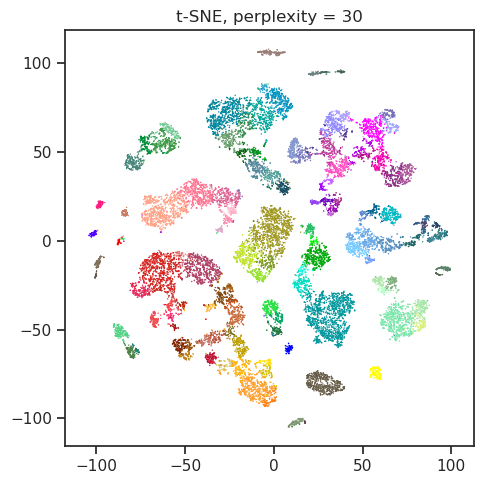

In [12]:
%%time

tsne = TSNE(
    n_components=2,
    perplexity=30,
    init="random",         # ⇢ matches FIt-SNE default
    metric="euclidean",
    learning_rate="auto",  # keeps behaviour unchanged across versions
    random_state=42,
    n_iter_without_progress=300,           # explicit; same as sklearn default
    n_jobs=-1,             # parallel Barnes–Hut tree build (sklearn ≥1.4)
)

tsne_default = tsne.fit_transform(X.astype(np.float32))  # X is your 50-PC matrix

# Plot
import matplotlib.pyplot as plt

plt.figure(figsize=(5, 5))
plt.gca().set_aspect("equal", adjustable="datalim")

plt.scatter(
    tsne_default[:, 0], tsne_default[:, 1],
    c=tasic2018['clusterColors'][tasic2018['clusters']],
    s=1, edgecolors="none"
)
plt.title("t-SNE, perplexity = 30")
plt.tight_layout()
plt.savefig('tSNE_plot.pdf', format='pdf', dpi=300, bbox_inches='tight')

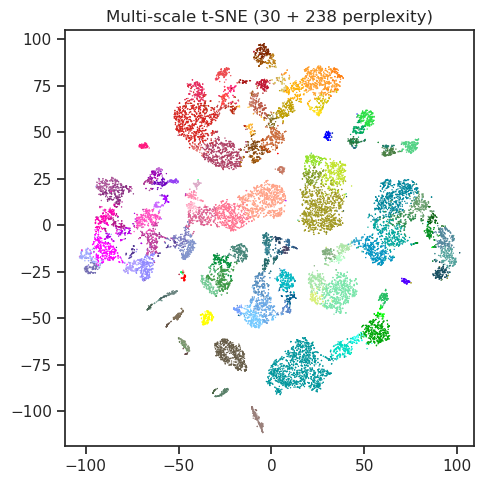

In [13]:
import openTSNE

pcaInit = X[:,:2] / np.std(X[:,0]) * 0.0001
tsne = openTSNE.TSNE(
    n_components=2,
    perplexity=[30, int(X.shape[0] / 100)],  # multi-scale!
    initialization=pcaInit,                  # same PCA seed
    n_jobs=-1,
    random_state=42,
    learning_rate=X.shape[0] / 12,
    n_iter=1000,
)

tsne_ours = tsne.fit(X.astype(np.float32))

plt.figure(figsize=(5, 5))
plt.gca().set_aspect("equal", adjustable="datalim")
plt.scatter(
    tsne_ours[:, 0], tsne_ours[:, 1],
    c=tasic2018['clusterColors'][tasic2018['clusters']],
    s=1, edgecolors="none"
)
plt.title("Multi-scale t-SNE (30 + {} perplexity)".format(int(X.shape[0] / 100)))
plt.tight_layout()
plt.savefig('tSNE_plot_high_perplexity.pdf', format='pdf', dpi=300, bbox_inches='tight')


In [14]:
'''
import joblib
import scipy.sparse as sp

# ── Pack everything ──────────────────────────────────────────
payload = dict(
    logCPM          = logCPM.astype(np.float32),        # dense (cells × 3 000)
    X_pca           = X.astype(np.float32),             # scores you already computed
    tasic2018       = {                                 # light-weight meta
        "genes"        : tasic2018["genes"],
        "clusters"     : tasic2018["clusters"],
        "areas"        : tasic2018["areas"],
        "clusterColors": tasic2018["clusterColors"],
        "clusterNames" : tasic2018["clusterNames"],
    },
    counts_sparse   = tasic2018["counts"].tocsr(),      # big CSR matrix
)

# ── Dump to disk (compressed with gzip) ─────────────────────
joblib.dump(payload, "tasic_checkpoint.joblib")
'''

'\nimport joblib\nimport scipy.sparse as sp\n\n# ── Pack everything ──────────────────────────────────────────\npayload = dict(\n    logCPM          = logCPM.astype(np.float32),        # dense (cells × 3 000)\n    X_pca           = X.astype(np.float32),             # scores you already computed\n    tasic2018       = {                                 # light-weight meta\n        "genes"        : tasic2018["genes"],\n        "clusters"     : tasic2018["clusters"],\n        "areas"        : tasic2018["areas"],\n        "clusterColors": tasic2018["clusterColors"],\n        "clusterNames" : tasic2018["clusterNames"],\n    },\n    counts_sparse   = tasic2018["counts"].tocsr(),      # big CSR matrix\n)\n\n# ── Dump to disk (compressed with gzip) ─────────────────────\njoblib.dump(payload, "tasic_checkpoint.joblib")\n'

In [15]:

%%time
import umap
import numpy as np
import matplotlib.pyplot as plt

# Reproducibility
np.random.seed(42)

umap_model = umap.UMAP(
    n_neighbors=15,      # size of local neighbourhood
    min_dist=0.3,        # how tightly points pack together
    metric="euclidean",  # same metric you used for t-SNE
    random_state=42
)

embedding_umap = umap_model.fit_transform(X.astype(np.float32))   # shape: (cells, 2)

/home/hongrui_liu/miniconda3/envs/rnaseq/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/hongrui_liu/miniconda3/envs/rnaseq/lib/python3.10/site-packages/sklearn/manifold/_spectral_embedding.py:328: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


CPU times: user 22.9 s, sys: 76.2 ms, total: 22.9 s
Wall time: 14.6 s


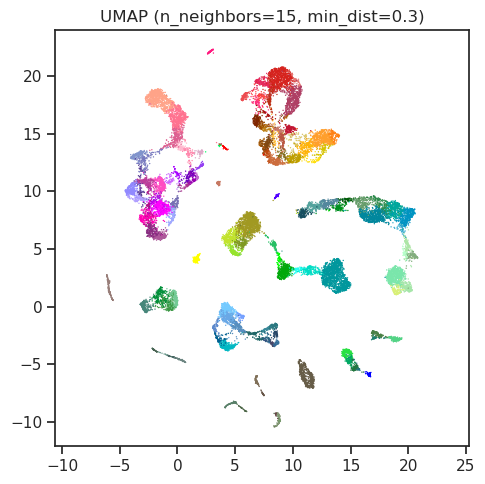

In [16]:
plt.figure(figsize=(5, 5))
plt.scatter(
    embedding_umap[:, 0], embedding_umap[:, 1],
    c=tasic2018['clusterColors'][tasic2018['clusters']],
    s=1, edgecolors='none'
)
plt.gca().set_aspect('equal', adjustable='datalim')
plt.title('UMAP (n_neighbors=15, min_dist=0.3)')
plt.tight_layout()